In [52]:
import numpy as np
import matplotlib.pyplot as plt



In [53]:
def gamblers_ruin(start, steps, p, m, change):
    q = 1-p
    step_set = np.array([-change, change])
    probs = np.array([q,p])
    random_steps = np.random.choice(step_set, steps, p=probs)
    random_walk = np.concatenate([[start], [start] + np.cumsum(random_steps)])
    for i in range(0, len(random_walk)):
        if random_walk[i] == 0 or random_walk[i] == m:
            for j in range(i+1, len(random_walk)):
                random_walk[j] = random_walk[i]
    return random_walk


Text(0, 0.5, 'Position')

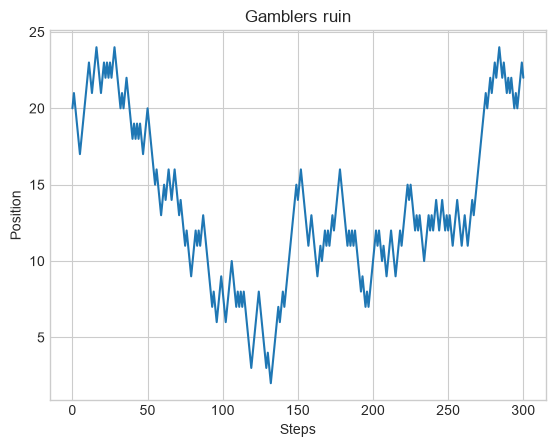

In [54]:
#singular path starting at 20 with p = 0.5 and a barrier at 40
path = gamblers_ruin(20,300,0.5, 40, 1)

plt.plot(path)
plt.title("Gamblers ruin")
plt.xlabel("Steps")
plt.ylabel("Position")

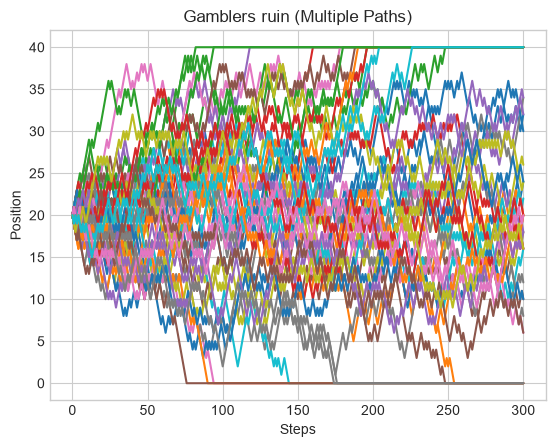

In [55]:
#multiple paths starting at 20 with p = 0.5 and a barrier at 40
paths = 50

for i in range(paths):
    path = gamblers_ruin(20,300,0.5, 40, 1)
    plt.plot(path)

plt.title("Gamblers ruin (Multiple Paths)")
plt.xlabel("Steps")
plt.ylabel("Position")
plt.show()


A standard Roulette wheel has 37 numbers (numbered 0 through 36) on a European and French roulette wheel, meaning if betting on black you have a 18/37 (\aprox 0.4865) chance of winning. Lets simulate the case of walking into a casino with £200 in chips betting £10 on black each spin and leaving only once becoming bankrupt, reaching a goal of £400 or after 300 spins when the casion closes.

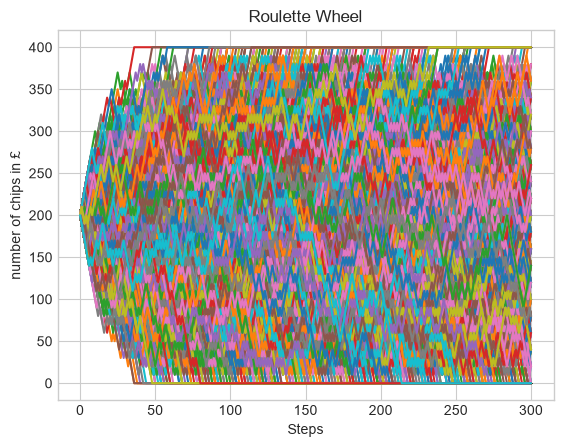

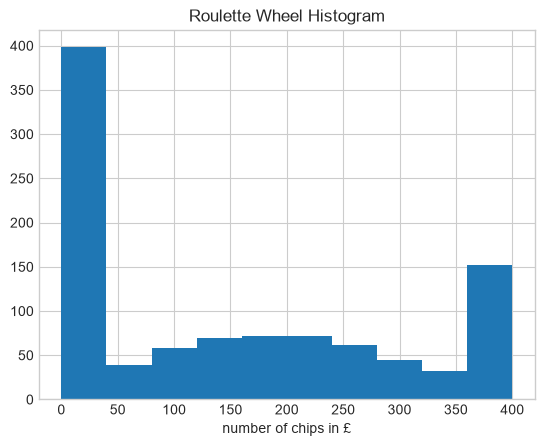

Text(0.5, 0, 'Case')

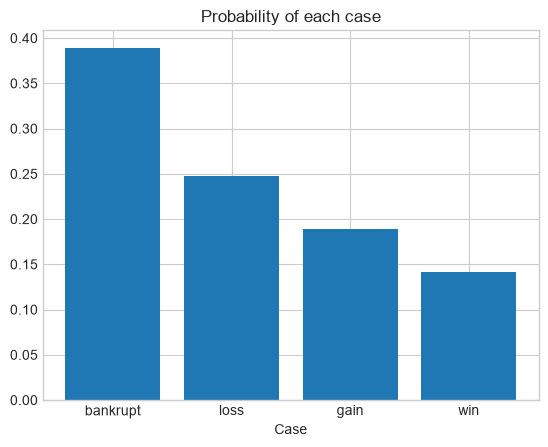

In [56]:
paths = 1000
final_positions = np.array([])

for i in range(paths):
    path = gamblers_ruin(200,300,0.4865, 400, 10)
    final_positions = np.append(final_positions, path[-1])
    plt.plot(path)

bankrupt = np.sum(final_positions == 0)/paths
loss     = np.sum((final_positions > 0) & (final_positions < 200))/paths
gain     = np.sum((final_positions > 200) & (final_positions < 400))/paths
win      = np.sum(final_positions == 400)/paths

cases = ["bankrupt", "loss", "gain", "win"]
count = [bankrupt, loss, gain, win]


plt.title("Roulette Wheel")
plt.xlabel("Steps")
plt.ylabel("number of chips in £")
plt.show()

plt.hist(final_positions)
plt.title("Roulette Wheel Histogram")
plt.xlabel("number of chips in £")
plt.show()

plt.bar(cases, count)
plt.title("Probability of each case")
plt.xlabel("Case")
